# Internal states at the final checkpoint (step 658032)

How are facts *stored* in the model once training has finished? This notebook
looks at the single-checkpoint internal-state dump for the **15-shot, top-10%%
exposure** eval set (1452 facts), produced by
`feature_extraction/eval_checkpoints.py`.

Unlike the trajectory notebook (which asks *when* a fact is learned), here every
fact is measured **once**, at the end of training, with a rich set of
internal features from a single teacher-forced forward pass:

- **Recall & confidence** — `correct` (substring match), `is_top1`, `gold_prob`,
  `gold_rank`, `answer_margin`, `pred_entropy`.
- **Logit lens** — `gold_rank_by_layer` / `gold_logit_by_layer` and the
  `resolution_depth` (the layer at which the gold answer first becomes top-1).
- **Geometry & compute** — `resid_norm_by_layer`, and MLP activity
  (`mlp_active_frac`, `mlp_participation`) at both the **answer** and **subject**
  token positions.

We ask: what separates a fact the model *knows* from one it doesn't, and *where*
in the network that knowledge appears?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- shared visual style (matches the trajectory notebook) ---
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
# correct = blue, incorrect = orange (colorblind-safe pair)
C_OK, C_NO = BLUE, ORANGE
pfmt = lambda v, p: f"{v:.0%}"

PARQUET = ("data/artifacts/recall/rotemab_15shot_top10_last_ckpt_internal/"
           "recall_step658032_15shot_top10pct.parquet")
df = pd.read_parquet(PARQUET)

# bring in relation type + exposure from the saved fact-properties table
props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv")
df = df.merge(props[["id", "prop", "num_shared_chunks"]], on="id", how="left")

# `excluded` facts (answer leaks into the prompt) are not scoreable -- keep a
# clean view for every rate/accuracy statistic, but note how many we drop.
ok = df[~df["excluded"]].reset_index(drop=True)
print(f"{len(df)} facts total | {df['excluded'].sum()} excluded | {len(ok)} scoreable")
print(f"correct = {ok['correct'].mean():.1%}   is_top1 = {ok['is_top1'].mean():.1%}")
df.shape

1452 facts total | 142 excluded | 1310 scoreable
correct = 41.5%   is_top1 = 20.2%


(1452, 36)

## 1 — Recall funnel

`correct` (a lenient substring match over the greedy generation) is met by far
more facts than `is_top1` (the gold answer is the single most likely next token).
The gap is the set of facts the model can *produce* but is not *confident* about.
`resolution` = the gold answer becomes top-1 at **some** layer under the logit
lens, even if it is not top-1 at the output.

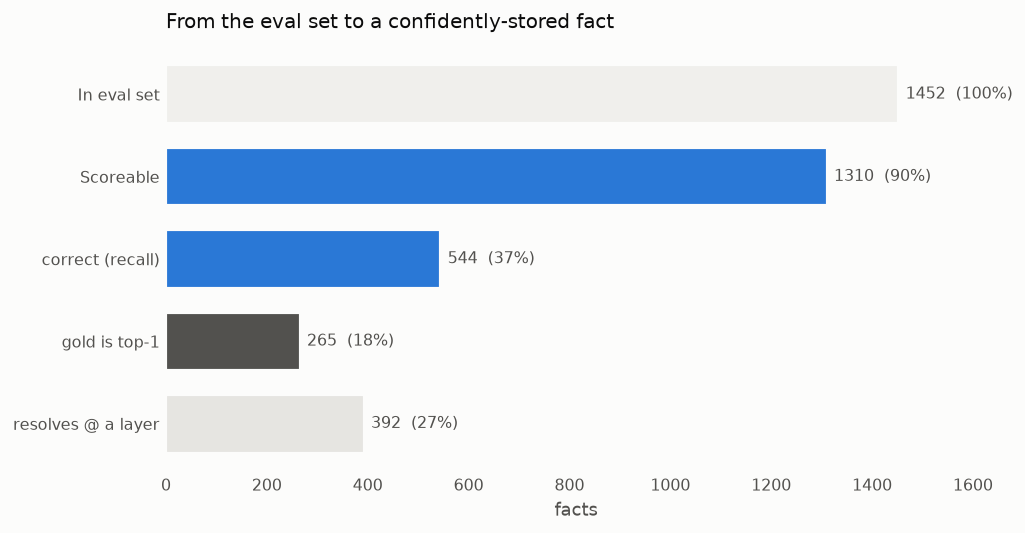

In [2]:
stages = {
    "In eval set":      len(df),
    "Scoreable":        len(ok),
    "correct (recall)": int(ok["correct"].sum()),
    "gold is top-1":    int(ok["is_top1"].sum()),
    "resolves @ a layer": int(ok["resolution_depth"].notna().sum()),
}
labels = list(stages)[::-1]
vals = [stages[k] for k in labels]

fig, ax = plt.subplots(figsize=(8, 4.2))
ypos = np.arange(len(labels))
bars = ax.barh(ypos, vals, color=[NEUTRAL, BLUE, BLUE, INK2, GRID][::-1],
               edgecolor=SURF, linewidth=1.2, height=0.7)
for i, v in enumerate(vals):
    ax.text(v + len(df) * 0.01, i, f"{v}  ({v/len(df):.0%})",
            va="center", fontsize=9, color=INK2)
ax.set_yticks(ypos, labels)
ax.set_xlim(0, len(df) * 1.12)
ax.set_xlabel("facts")
ax.set_title("From the eval set to a confidently-stored fact", loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

## 2 — Confidence separates right from wrong

Split every fact by whether it was recalled `correct`ly, and compare the
answer-head signals. Correct facts sit at rank 1 with an order-of-magnitude
higher gold probability, a near-zero (vs. very negative) margin against the
top competitor, and much lower predictive entropy.

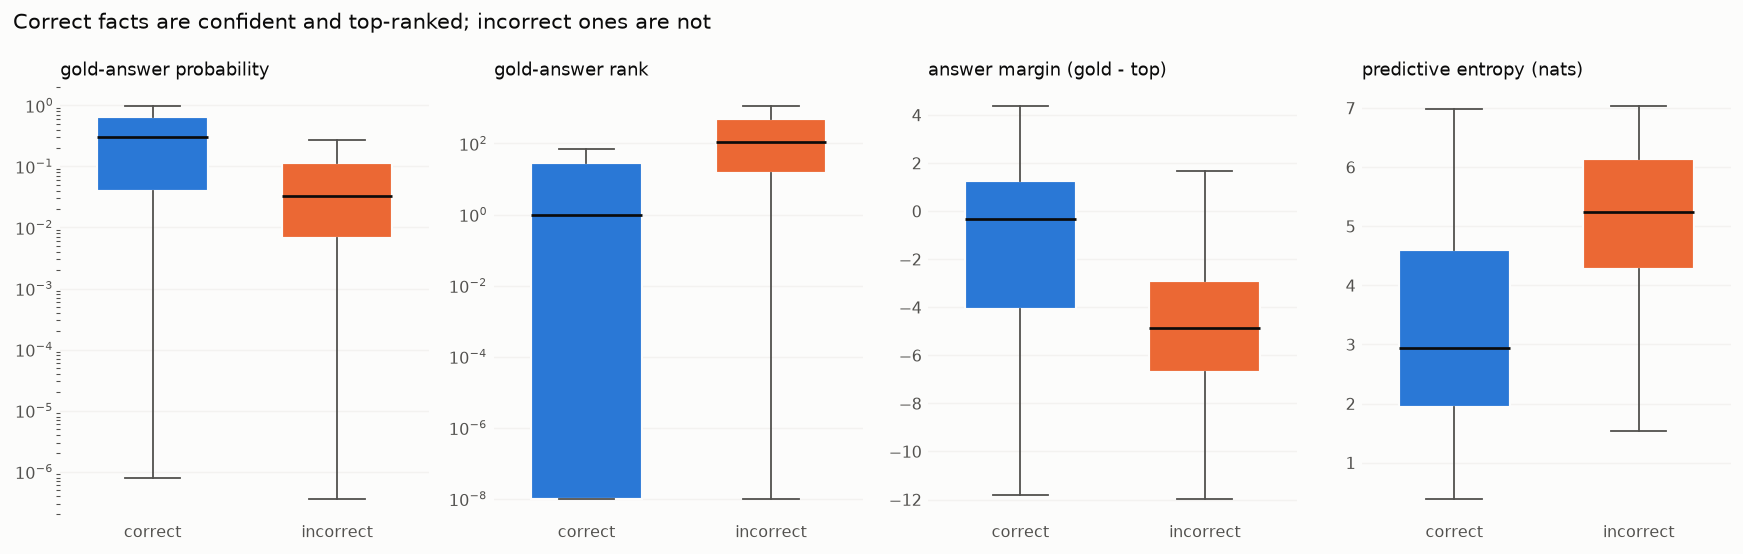

In [3]:
c = ok["correct"].to_numpy()
PANELS = [
    ("gold_prob",     "gold-answer probability",     True),
    ("gold_rank",     "gold-answer rank",            True),
    ("answer_margin", "answer margin (gold - top)",  False),
    ("pred_entropy",  "predictive entropy (nats)",   False),
]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.3))
for ax, (col, label, log) in zip(axes, PANELS):
    a = ok.loc[c, col].to_numpy(dtype=float)
    b = ok.loc[~c, col].to_numpy(dtype=float)
    if log:
        a = np.clip(a, 1e-8, None); b = np.clip(b, 1e-8, None)
    bp = ax.boxplot([a, b], patch_artist=True, widths=0.6, showfliers=False,
                    medianprops=dict(color=INK, lw=1.5),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, col_ in zip(bp["boxes"], (C_OK, C_NO)):
        patch.set_facecolor(col_); patch.set_edgecolor(SURF); patch.set_linewidth(1.2)
    if log:
        ax.set_yscale("log")
    ax.set_xticks([1, 2], ["correct", "incorrect"], fontsize=9)
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Correct facts are confident and top-ranked; incorrect ones are not",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## 3 — The logit lens: *where* a fact resolves

Reading the gold answer's rank out of each layer's residual stream shows the
answer being assembled with depth. For **correct** facts the gold token plunges
from rank ~10^4 to rank 1 in the last third of the network; for **incorrect**
facts it stalls around rank ~100 and never makes it to the top.

`resolution_depth` records the first layer at which gold is top-1 -- only about a
third of scoreable facts ever reach it, and those that do cluster around the same
depth (see the right-hand panel).

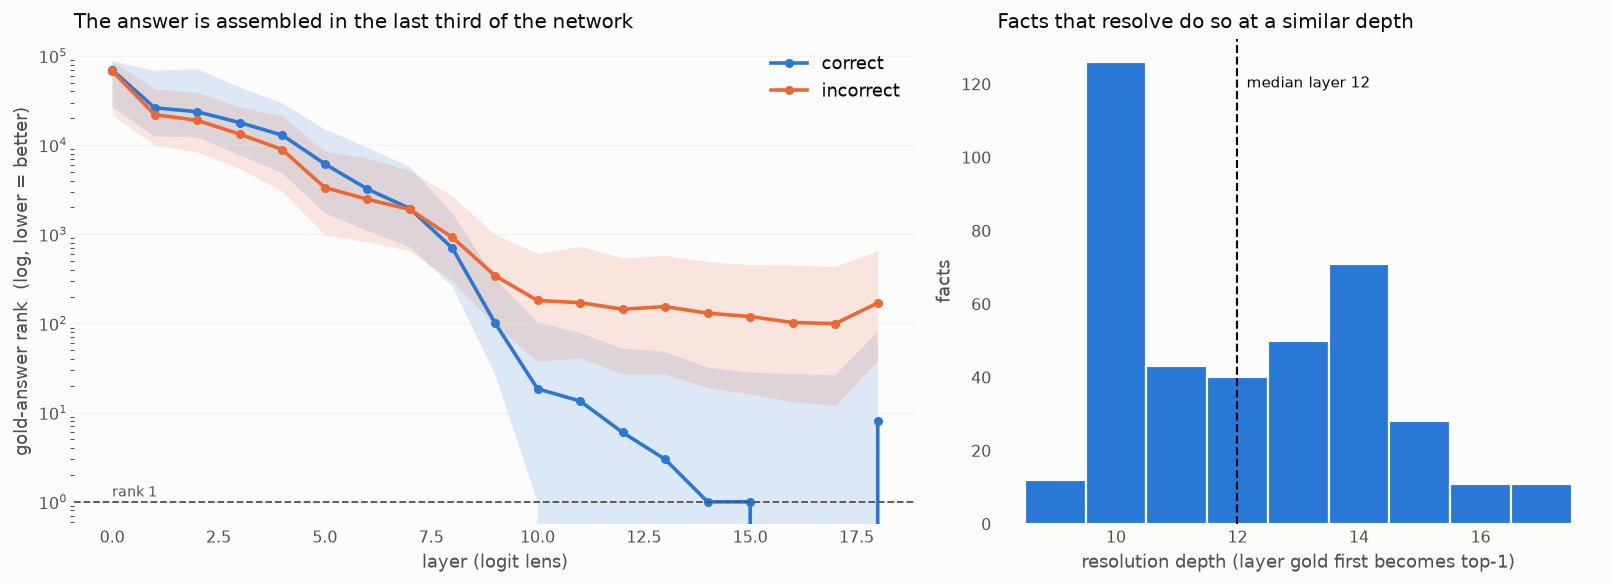

In [4]:
R = np.vstack(ok["gold_rank_by_layer"].to_numpy())      # (n, 19)
n_layer = R.shape[1]
xl = np.arange(n_layer)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6),
                               gridspec_kw={"width_ratios": [1.4, 1]})

# (a) per-layer gold-rank trajectory, correct vs incorrect (median + IQR)
for grp, colr, name in [(c, C_OK, "correct"), (~c, C_NO, "incorrect")]:
    med = np.median(R[grp], axis=0)
    q1 = np.percentile(R[grp], 25, axis=0)
    q3 = np.percentile(R[grp], 75, axis=0)
    ax1.fill_between(xl, q1, q3, color=colr, alpha=0.15, linewidth=0)
    ax1.plot(xl, med, color=colr, lw=2, marker="o", ms=4, label=name)
ax1.axhline(1, color=INK2, ls="--", lw=1)
ax1.text(0, 1.15, "rank 1", color=INK2, fontsize=8)
ax1.set_yscale("log")
ax1.set_xlabel("layer (logit lens)")
ax1.set_ylabel("gold-answer rank  (log, lower = better)")
ax1.set_title("The answer is assembled in the last third of the network", loc="left")
ax1.grid(axis="y", alpha=0.4)
ax1.legend(loc="upper right")

# (b) resolution-depth distribution (facts that ever reach top-1)
rd = ok["resolution_depth"].dropna().to_numpy()
ax2.hist(rd, bins=np.arange(rd.min() - 0.5, rd.max() + 1.5), color=BLUE,
         edgecolor=SURF, linewidth=1.2)
ax2.axvline(np.median(rd), color=INK, ls="--", lw=1.2)
ax2.text(np.median(rd) + 0.15, ax2.get_ylim()[1] * 0.9,
         f"median layer {np.median(rd):.0f}", color=INK, fontsize=8.5)
ax2.set_xlabel("resolution depth (layer gold first becomes top-1)")
ax2.set_ylabel("facts")
ax2.set_title("Facts that resolve do so at a similar depth", loc="left")

for ax in (ax1, ax2):
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()

## 4 — Geometry and compute across depth

The residual-stream norm and MLP activity by layer show *where* the network does
its work. MLP **participation** (how many neurons carry most of the mass) is read
at both the **answer** and **subject** token positions -- a sparser, more focused
answer representation tends to go with a confidently-stored fact.

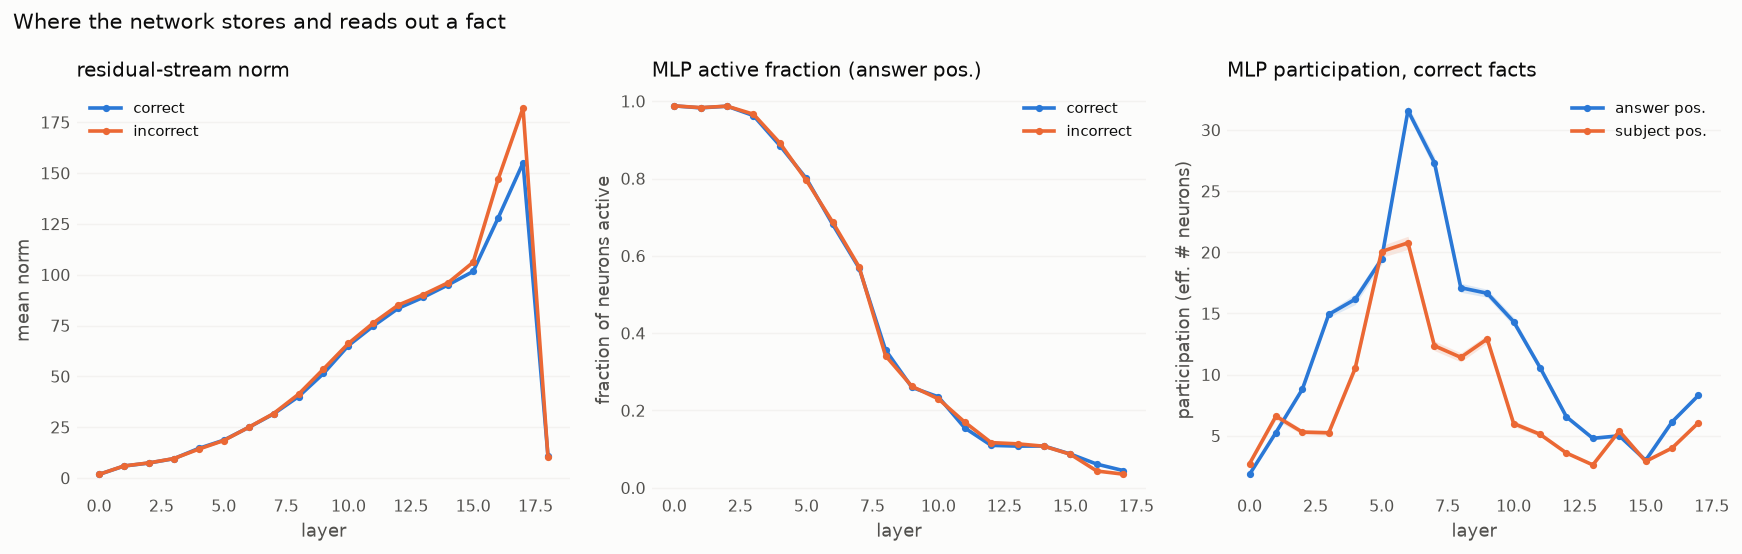

In [5]:
RN  = np.vstack(ok["resid_norm_by_layer"].to_numpy())            # (n,19)
MA  = np.vstack(ok["mlp_active_frac_by_layer"].to_numpy())        # (n,18) answer
MP  = np.vstack(ok["mlp_participation_by_layer"].to_numpy())      # (n,18) answer
MPs = np.vstack(ok["mlp_participation_by_layer_subj"].to_numpy()) # (n,18) subject

def band(ax, X, grp, colr, name):
    m = np.mean(X[grp], axis=0)
    se = np.std(X[grp], axis=0) / np.sqrt(grp.sum())
    x = np.arange(X.shape[1])
    ax.fill_between(x, m - se, m + se, color=colr, alpha=0.15, linewidth=0)
    ax.plot(x, m, color=colr, lw=2, marker="o", ms=3, label=name)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
# residual norm
for grp, colr, nm in [(c, C_OK, "correct"), (~c, C_NO, "incorrect")]:
    band(axes[0], RN, grp, colr, nm)
axes[0].set_title("residual-stream norm", loc="left")
axes[0].set_ylabel("mean norm")
# mlp active fraction (answer)
for grp, colr, nm in [(c, C_OK, "correct"), (~c, C_NO, "incorrect")]:
    band(axes[1], MA, grp, colr, nm)
axes[1].set_title("MLP active fraction (answer pos.)", loc="left")
axes[1].set_ylabel("fraction of neurons active")
# participation: answer vs subject (correct facts only, to compare positions)
band(axes[2], MP,  c, BLUE,   "answer pos.")
band(axes[2], MPs, c, ORANGE, "subject pos.")
axes[2].set_title("MLP participation, correct facts", loc="left")
axes[2].set_ylabel("participation (eff. # neurons)")

for ax in axes:
    ax.set_xlabel("layer")
    ax.grid(axis="y", alpha=0.4)
    ax.tick_params(length=0)
    ax.legend(loc="best", fontsize=8.5)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Where the network stores and reads out a fact", x=0.01, ha="left",
             fontsize=11.5)
fig.tight_layout()

## 5 — Does relation type and exposure explain internal confidence?

Tying the internal view back to the fact metadata: recall accuracy varies sharply
by relation type, and -- echoing the trajectory notebook -- relations whose facts
co-occur more often in training end up with higher gold probability at the final
checkpoint. Exposure doesn't just decide *whether* a fact is learned; it shapes
*how confidently* it is stored.

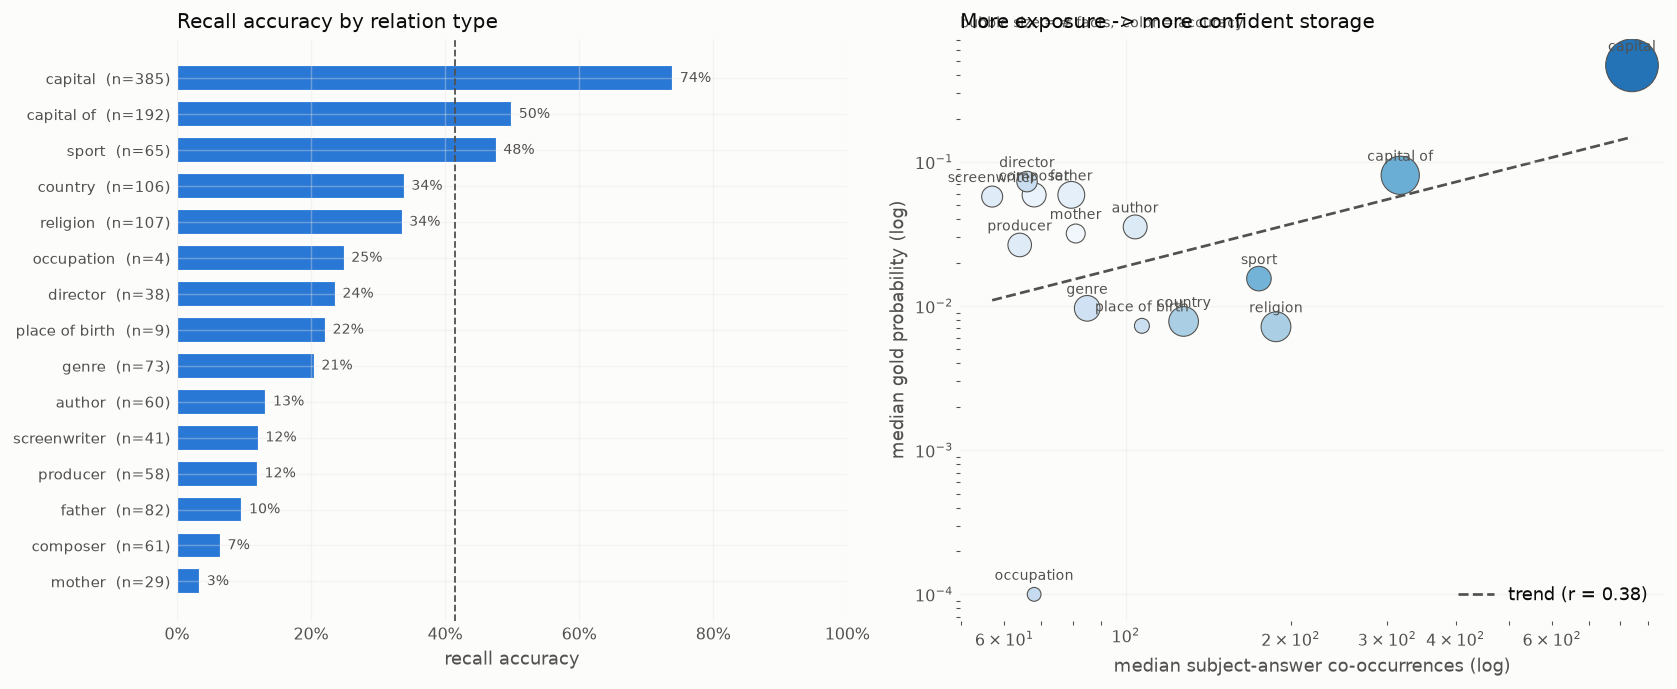

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4),
                               gridspec_kw={"width_ratios": [1, 1.05]})

# (a) accuracy by relation type
byp = ok.groupby("prop")["correct"].agg(["mean", "count"]).sort_values("mean")
yp = np.arange(len(byp))
ax1.barh(yp, byp["mean"], color=BLUE, edgecolor=SURF, linewidth=1.2, height=0.72)
for i, m in enumerate(byp["mean"]):
    ax1.text(m + 0.01, i, f"{m:.0%}", va="center", fontsize=8, color=INK2)
ax1.axvline(ok["correct"].mean(), color=INK2, ls="--", lw=1)
ax1.set_yticks(yp, [f"{p}  (n={n})" for p, n in zip(byp.index, byp['count'])],
               fontsize=8.5)
ax1.set_xlim(0, 1)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax1.set_xlabel("recall accuracy")
ax1.set_title("Recall accuracy by relation type", loc="left")

# (b) per-relation: exposure vs internal confidence
gp = ok.groupby("prop").agg(gold_prob=("gold_prob", "median"),
                            shared=("num_shared_chunks", "median"),
                            acc=("correct", "mean"),
                            n=("id", "size"))
x = gp["shared"].clip(lower=1)
y = gp["gold_prob"].clip(lower=1e-4)
lx = np.log10(x)
b, a = np.polyfit(lx, np.log10(y), 1)
r = np.corrcoef(lx, np.log10(y))[0, 1]
xs = np.linspace(lx.min(), lx.max(), 40)
ax2.plot(10**xs, 10**(a + b * xs), color=INK2, ls="--", lw=1.5,
         label=f"trend (r = {r:.2f})", zorder=1)
ax2.scatter(x, y, s=(gp["n"] / gp["n"].max() * 800) + 50, c=gp["acc"],
            cmap="Blues", vmin=0, vmax=1, edgecolor=INK2, linewidth=0.6, zorder=2)
for p in gp.index:
    ax2.annotate(p, (x[p], y[p]), fontsize=7.5, color=INK2,
                 xytext=(0, 8), textcoords="offset points", ha="center")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("median subject-answer co-occurrences (log)")
ax2.set_ylabel("median gold probability (log)")
ax2.set_title("More exposure -> more confident storage", loc="left")
ax2.legend(loc="lower right")
ax2.text(0.0, 1.02, "bubble size = # facts,  color = accuracy",
         transform=ax2.transAxes, fontsize=8, color=INK2)

for ax in (ax1, ax2):
    ax.grid(axis="both", alpha=0.35)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()